# Plane Waves in Multilayer Media: The Transfer-Matrix Method

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jman4162/RF-and-Antenna-Tutorials/blob/main/Multilayer_Media_Transfer_Matrix_Method_Tutorial.ipynb)

This notebook builds a transfer-matrix solver for plane waves crossing a stack of homogeneous layers, checks it against closed-form results, and then applies it to two problems from a Virginia Tech ECE 5105 final exam (December 2015): evanescent coupling across a three-layer stack, and the guided TM mode of an asymmetric dielectric slab waveguide. The original MATLAB solutions are in [electromagnetics-work-samples](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/dielectric-slab-boundaries).

Topics:

- Fresnel coefficients for TE (s) and TM (p) polarization, the Brewster angle and total internal reflection (TIR)
- The transfer matrix of a layer stack and how it conserves energy
- Thin-film interference: quarter-wave antireflection coatings and Bragg mirrors
- Frustrated TIR: tunneling through an evanescent gap
- Guided modes as poles of the reflection coefficient

Every numerical result below is checked with an `assert` against an independent closed-form result, so the notebook fails loudly if the solver is wrong.

## Conventions

- Time-harmonic fields are $\mathrm{Re}\{\tilde{E}\,e^{-i\omega t}\}$, so a forward wave in a layer is $e^{+i k_z z}$.
- Passive media have $\mathrm{Im}\,n \ge 0$, and we choose $\mathrm{Im}\,k_z \ge 0$ so evanescent fields decay away from their source.
- Layers are stacked along $z$ and the plane of incidence is $xz$. The tangential wavenumber $\beta = k_0 n_0 \sin\theta_0$ is the same in every layer (phase matching, which is Snell's law).
- TE (s) polarization has $\mathbf{E}$ along $y$; TM (p) polarization has $\mathbf{H}$ along $y$.

Textbooks that use $e^{+j\omega t}$ (Balanis, Pozar) give the complex conjugate of the coefficients here. Reflectance and transmittance are the same in both conventions.

## Theory

In layer $j$ with refractive index $n_j$, the normal wavenumber is

$$k_{z,j} = \sqrt{k_0^2 n_j^2 - \beta^2}, \qquad k_0 = 2\pi/\lambda_0 .$$

At the interface from layer $j$ to layer $k$ the Fresnel coefficients are

$$r_s = \frac{k_{z,j} - k_{z,k}}{k_{z,j} + k_{z,k}}, \qquad t_s = \frac{2k_{z,j}}{k_{z,j} + k_{z,k}},$$

$$r_p = \frac{n_k^2 k_{z,j} - n_j^2 k_{z,k}}{n_k^2 k_{z,j} + n_j^2 k_{z,k}}, \qquad t_p = \frac{2 n_j n_k k_{z,j}}{n_k^2 k_{z,j} + n_j^2 k_{z,k}} .$$

Write the forward and backward wave amplitudes at the start of each layer as a vector $(v_j, w_j)$. Crossing an interface multiplies by $I_{jk} = \frac{1}{t_{jk}}\begin{pmatrix}1 & r_{jk}\\ r_{jk} & 1\end{pmatrix}$, and crossing a layer of thickness $d_j$ multiplies by $P_j = \mathrm{diag}(e^{-i\delta_j}, e^{+i\delta_j})$ with $\delta_j = k_{z,j} d_j$. For a stack with semi-infinite media $0$ and $N$,

$$M = I_{01} P_1 I_{12} P_2 \cdots P_{N-1} I_{N-1,N}, \qquad r = \frac{M_{21}}{M_{11}}, \qquad t = \frac{1}{M_{11}} .$$

The power fractions are $R = |r|^2$ and

$$T_s = |t|^2 \frac{\mathrm{Re}(n_N \cos\theta_N)}{\mathrm{Re}(n_0\cos\theta_0)}, \qquad T_p = |t|^2 \frac{\mathrm{Re}(n_N \cos\theta_N^*)}{\mathrm{Re}(n_0\cos\theta_0^*)},$$

with $\cos\theta_j = k_{z,j}/(k_0 n_j)$. This is the formulation used by Byrnes (2016); for lossless layers $R + T = 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

In [2]:
def normal_wavenumbers(n, beta, k0):
    """k_z in each layer, with the branch Im(k_z) >= 0 (decaying evanescent fields)."""
    kz = np.sqrt((k0 * np.asarray(n, dtype=complex)) ** 2 - beta**2)
    return np.where(kz.imag < 0, -kz, kz)


def fresnel(nj, nk, kzj, kzk, pol):
    """Reflection and transmission amplitude coefficients from layer j into layer k."""
    if pol == "s":
        return (kzj - kzk) / (kzj + kzk), 2 * kzj / (kzj + kzk)
    den = nk**2 * kzj + nj**2 * kzk
    return (nk**2 * kzj - nj**2 * kzk) / den, 2 * nj * nk * kzj / den


def transfer_matrix(n, d, pol, lam0, theta0=0.0, beta=None):
    """2x2 transfer matrix of a stack. n, d list every medium; d[0] and d[-1] are ignored.

    Pass either the incidence angle theta0 (in medium 0) or the tangential wavenumber beta.
    """
    n = np.asarray(n, dtype=complex)
    k0 = 2 * np.pi / lam0
    if beta is None:
        beta = k0 * n[0] * np.sin(theta0)
    kz = normal_wavenumbers(n, beta, k0)
    r, t = fresnel(n[0], n[1], kz[0], kz[1], pol)
    M = np.array([[1, r], [r, 1]], dtype=complex) / t
    for j in range(1, len(n) - 1):
        delta = kz[j] * d[j]
        P = np.diag([np.exp(-1j * delta), np.exp(1j * delta)])
        r, t = fresnel(n[j], n[j + 1], kz[j], kz[j + 1], pol)
        M = M @ P @ (np.array([[1, r], [r, 1]], dtype=complex) / t)
    return M, kz


def stack_rt(n, d, pol, lam0, theta0=0.0):
    """Amplitude coefficients r, t and power fractions R, T for a plane wave incident from medium 0."""
    n = np.asarray(n, dtype=complex)
    M, kz = transfer_matrix(n, d, pol, lam0, theta0)
    r, t = M[1, 0] / M[0, 0], 1 / M[0, 0]
    k0 = 2 * np.pi / lam0
    cos0, cosN = kz[0] / (k0 * n[0]), kz[-1] / (k0 * n[-1])
    if pol == "s":
        T = abs(t) ** 2 * (n[-1] * cosN).real / (n[0] * cos0).real
    else:
        T = abs(t) ** 2 * (n[-1] * np.conj(cosN)).real / (n[0] * np.conj(cos0)).real
    return r, t, abs(r) ** 2, T

## Checks against closed-form results

1. A single interface must reproduce the textbook Fresnel equations, and $R_p = 0$ at the Brewster angle $\theta_B = \arctan(n_2/n_1)$.
2. Beyond the critical angle, a single interface reflects everything ($R = 1$).
3. Lossless stacks conserve energy: $R + T = 1$ for random stacks, angles and polarizations, including evanescent layers.
4. A quarter-wave antireflection coating with $n_c = \sqrt{n_0 n_s}$ and $d = \lambda_0/(4n_c)$ gives $R = 0$ at normal incidence.
5. A quarter-wave Bragg mirror matches the optical-admittance recursion $Y \leftarrow n_\ell^2 / Y$, which is derived independently of the transfer matrix.

In [3]:
# 1. Fresnel equations and Brewster angle (air to glass)
n1, n2 = 1.0, 1.5
for th in np.radians([0, 20, 45, 70, 85]):
    c1, c2 = np.cos(th), np.sqrt(1 - (n1 * np.sin(th) / n2) ** 2)
    rs_closed = (n1 * c1 - n2 * c2) / (n1 * c1 + n2 * c2)
    rp_closed = (n2 * c1 - n1 * c2) / (n2 * c1 + n1 * c2)
    assert abs(stack_rt([n1, n2], [np.inf, np.inf], "s", 1.0, th)[0] - rs_closed) < 1e-12
    assert abs(stack_rt([n1, n2], [np.inf, np.inf], "p", 1.0, th)[0] - rp_closed) < 1e-12
theta_B = np.arctan(n2 / n1)
Rp_brewster = stack_rt([n1, n2], [np.inf, np.inf], "p", 1.0, theta_B)[2]
assert Rp_brewster < 1e-25

# 2. Total internal reflection (glass to air beyond the critical angle)
theta_c = np.arcsin(1 / 1.5)
for th in np.linspace(theta_c + 1e-3, np.pi / 2 - 1e-3, 7):
    for pol in "sp":
        assert abs(stack_rt([1.5, 1.0], [np.inf, np.inf], pol, 1.0, th)[2] - 1) < 1e-12

# 3. Energy conservation for random lossless stacks
rng = np.random.default_rng(0)
worst = 0.0
for _ in range(300):
    N = rng.integers(1, 7)
    n = np.r_[rng.uniform(1, 3), rng.uniform(1, 4, N), rng.uniform(1, 3)]
    d = np.r_[np.inf, rng.uniform(0.05, 2.0, N), np.inf]
    _, _, R, T = stack_rt(n, d, rng.choice(["s", "p"]), 1.0, rng.uniform(0, 0.99 * np.pi / 2))
    worst = max(worst, abs(R + T - 1))
assert worst < 1e-12

# 4. Quarter-wave antireflection coating on glass
lam0, ns = 0.55, 1.5
nc = np.sqrt(1.0 * ns)
R_ar = stack_rt([1.0, nc, ns], [np.inf, lam0 / (4 * nc), np.inf], "s", lam0)[2]
assert R_ar < 1e-25

# 5. Bragg mirror vs the admittance recursion
nH, nL, n_sub, pairs = 2.35, 1.38, 1.52, 6
n = [1.0] + [nH, nL] * pairs + [n_sub]
d = [np.inf] + [1 / (4 * nH), 1 / (4 * nL)] * pairs + [np.inf]
Y = n_sub
for n_layer in [nL, nH] * pairs:
    Y = n_layer**2 / Y
R_bragg_closed = ((1.0 - Y) / (1.0 + Y)) ** 2
R_bragg = stack_rt(n, d, "s", 1.0)[2]
assert abs(R_bragg - R_bragg_closed) < 1e-12

print(f"Brewster angle {np.degrees(theta_B):.2f} deg: Rp = {Rp_brewster:.1e}")
print(f"Max |R + T - 1| over 300 random stacks: {worst:.1e}")
print(f"Quarter-wave AR coating: R = {R_ar:.1e}")
print(f"6-pair Bragg mirror: R = {R_bragg:.10f} (closed form {R_bragg_closed:.10f})")
print("All checks passed.")

Brewster angle 56.31 deg: Rp = 3.2e-33
Max |R + T - 1| over 300 random stacks: 1.0e-14
Quarter-wave AR coating: R = 3.0e-33
6-pair Bragg mirror: R = 0.9955843905 (closed form 0.9955843905)
All checks passed.


## Fresnel reflectance and a Bragg mirror

The left panel shows the single-interface reflectance for air to glass (Brewster angle near 56.3°) and glass to air (critical angle near 41.8°). The right panel shows the reflectance spectrum of quarter-wave Bragg mirrors designed for $\lambda_0 = 1$; adding pairs raises the peak and steepens the band edges without changing the stop-band width much.

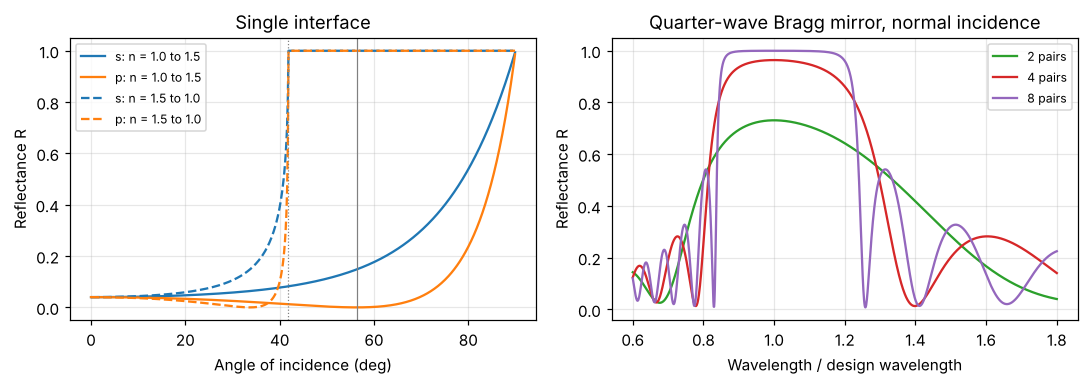

In [4]:
theta = np.radians(np.linspace(0, 89.9, 600))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
for (na, nb), style in [((1.0, 1.5), "-"), ((1.5, 1.0), "--")]:
    for pol, color in [("s", "C0"), ("p", "C1")]:
        R = [stack_rt([na, nb], [np.inf, np.inf], pol, 1.0, th)[2] for th in theta]
        ax1.plot(np.degrees(theta), R, style, color=color, label=f"{pol}: n = {na} to {nb}")
ax1.axvline(np.degrees(theta_B), color="0.5", lw=0.8)
ax1.axvline(np.degrees(theta_c), color="0.5", lw=0.8, ls=":")
ax1.set(xlabel="Angle of incidence (deg)", ylabel="Reflectance R", title="Single interface")
ax1.legend(fontsize=8)

lam = np.linspace(0.6, 1.8, 1200)
for pairs, color in [(2, "C2"), (4, "C3"), (8, "C4")]:
    n = [1.0] + [nH, nL] * pairs + [n_sub]
    d = [np.inf] + [1 / (4 * nH), 1 / (4 * nL)] * pairs + [np.inf]
    ax2.plot(lam, [stack_rt(n, d, "s", w)[2] for w in lam], color=color, label=f"{pairs} pairs")
ax2.set(xlabel="Wavelength / design wavelength", ylabel="Reflectance R", title="Quarter-wave Bragg mirror, normal incidence")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Exam problem 1: a TE wave crossing a three-layer stack

The exam problem: a TE plane wave with $\omega = 3\times10^{11}$ rad/s ($\lambda_0 \approx 6.28$ mm) is incident at $\theta_i = 60°$ from a medium with $\varepsilon_1 = 4\varepsilon_0$ onto a middle layer of thickness $d$, followed by $\varepsilon_3 = 4\varepsilon_0$. Two cases: (A) $\varepsilon_2 = \varepsilon_0$ and (B) $\varepsilon_2 = 8\varepsilon_0$, with $d$ swept from 0.01 to 10 mm.

The exam used $\varepsilon_0 = 8.854\times10^{-12}$ F/m and $\mu_0 = 4\pi\times10^{-7}$ H/m. Using the same constants reproduces the wavenumber table in the original report.

In [5]:
eps0, mu0 = 8.854e-12, 4e-7 * np.pi
omega, theta_i = 3e11, np.radians(60)
k0 = omega * np.sqrt(eps0 * mu0)
lam0 = 2 * np.pi / k0
n1 = 2.0                                   # eps_r = 4
nA, nB = 1.0, np.sqrt(8.0)                 # eps_r = 1 (Case A) and 8 (Case B)

beta = k0 * n1 * np.sin(theta_i)
kx1 = k0 * n1 * np.cos(theta_i)
kappa_A = np.sqrt(beta**2 - (k0 * nA) ** 2)    # Case A: evanescent in layer 2
kx2_B = np.sqrt((k0 * nB) ** 2 - beta**2)      # Case B: propagating in layer 2

report = {"kx1": 1000.68, "beta": 1733.23, "kappa_A": 1415.18, "kx2_B": 2237.60}
ours = {"kx1": kx1, "beta": beta, "kappa_A": kappa_A, "kx2_B": kx2_B}
for key in report:
    assert abs(ours[key] - report[key]) < 0.01, key
    print(f"{key:8s} = {ours[key]:9.2f} 1/m   (report: {report[key]:.2f})")
print(f"lambda_0 = {lam0 * 1e3:.3f} mm")

kx1      =   1000.68 1/m   (report: 1000.68)
beta     =   1733.23 1/m   (report: 1733.23)
kappa_A  =   1415.18 1/m   (report: 1415.18)
kx2_B    =   2237.59 1/m   (report: 2237.60)
lambda_0 = 6.279 mm


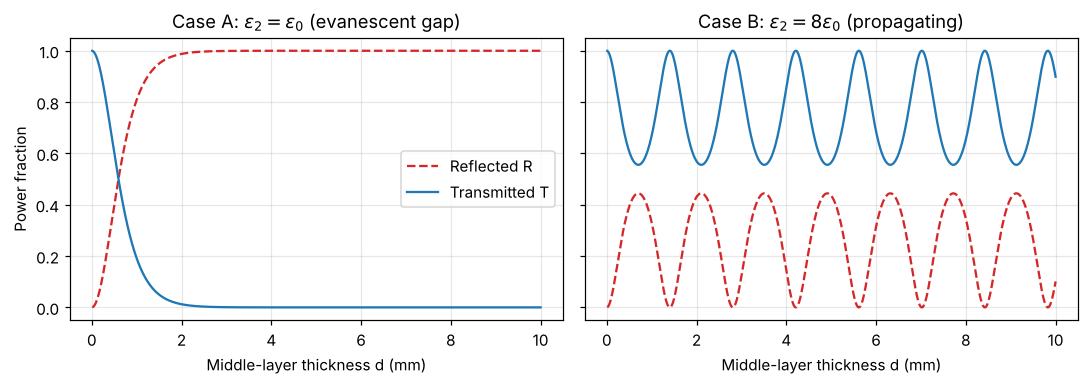

Case A: T = 1.23% at d = 2 mm and 0.073% at d = 3 mm (report: below 1.3% and below 0.1%)
Case B: minimum T = 0.556 (report: about 0.56)


In [6]:
d = np.linspace(0.01e-3, 10e-3, 2000)
RT_A = np.array([stack_rt([n1, nA, n1], [np.inf, x, np.inf], "s", lam0, theta_i)[2:] for x in d])
RT_B = np.array([stack_rt([n1, nB, n1], [np.inf, x, np.inf], "s", lam0, theta_i)[2:] for x in d])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, RT, title in [(axes[0], RT_A, "Case A: $\\varepsilon_2 = \\varepsilon_0$ (evanescent gap)"),
                      (axes[1], RT_B, "Case B: $\\varepsilon_2 = 8\\varepsilon_0$ (propagating)")]:
    ax.plot(d * 1e3, RT[:, 0], "C3--", label="Reflected R")
    ax.plot(d * 1e3, RT[:, 1], "C0", label="Transmitted T")
    ax.set(xlabel="Middle-layer thickness d (mm)", title=title)
axes[0].set_ylabel("Power fraction")
axes[0].legend()
plt.tight_layout()
plt.show()

T_2mm, T_3mm = np.interp([2e-3, 3e-3], d, RT_A[:, 1])
print(f"Case A: T = {100 * T_2mm:.2f}% at d = 2 mm and {100 * T_3mm:.3f}% at d = 3 mm "
      "(report: below 1.3% and below 0.1%)")
print(f"Case B: minimum T = {RT_B[:, 1].min():.3f} (report: about 0.56)")

**Case A (frustrated TIR).** Here $\beta = 1733$ m$^{-1}$ exceeds $k_2 = k_0 = 1001$ m$^{-1}$, so the field in the middle layer is evanescent, $\propto e^{\pm\kappa x}$ with $\kappa = \sqrt{\beta^2 - k_0^2} = 1415$ m$^{-1}$. Power still reaches layer 3 by tunneling, and for $\kappa d \gg 1$ the transmittance falls as $T \propto e^{-2\kappa d}$.

**Case B (Fabry–Pérot resonances).** The middle layer is denser, the wave propagates in it, and multiple reflections interfere. For a symmetric layer, $R = 0$ whenever $k_{x2} d = m\pi$, and the peak reflectance follows from the Airy formula, $R_{\max} = 4r^2/(1 + r^2)^2$, where $r$ is the single-interface Fresnel coefficient.

The next cell checks all three statements numerically.

In [7]:
# Case A: decay rate of T at large thickness should be -2*kappa
d_fit = np.linspace(4e-3, 8e-3, 60)
T_fit = [stack_rt([n1, nA, n1], [np.inf, x, np.inf], "s", lam0, theta_i)[3] for x in d_fit]
slope = np.polyfit(d_fit, np.log(T_fit), 1)[0]
assert abs(slope / (-2 * kappa_A) - 1) < 1e-4

# Case B: zero reflection at half-wave thickness (normal to the layer)
R_halfwave = stack_rt([n1, nB, n1], [np.inf, np.pi / kx2_B, np.inf], "s", lam0, theta_i)[2]
assert R_halfwave < 1e-20

# Case B: peak reflectance from the Airy formula
r12 = (kx1 - kx2_B) / (kx1 + kx2_B)
R_max_airy = 4 * r12**2 / (1 + r12**2) ** 2
assert abs(RT_B[:, 0].max() - R_max_airy) < 1e-5

print(f"Fitted decay rate {slope:.1f} 1/m vs -2*kappa = {-2 * kappa_A:.1f} 1/m")
print(f"R at d = pi/kx2 = {np.pi / kx2_B * 1e3:.3f} mm: {R_halfwave:.1e}")
print(f"Peak R: {RT_B[:, 0].max():.5f} vs Airy formula {R_max_airy:.5f}")

Fitted decay rate -2830.4 1/m vs -2*kappa = -2830.4 1/m
R at d = pi/kx2 = 1.404 mm: 1.6e-32
Peak R: 0.44444 vs Airy formula 0.44444


## Exam problem 2: the guided TM mode of an asymmetric slab

The exam's waveguide has a core with $\varepsilon = 9\varepsilon_0$ ($n = 3$) and thickness $d = 0.5$ µm between claddings with $\varepsilon = 2\varepsilon_0$ and $4\varepsilon_0$, at $\lambda_0 = 1$ µm. A guided mode is a field that exists with no incident wave. In transfer-matrix terms the reflection coefficient $r = M_{21}/M_{11}$ has a pole, so guided modes satisfy

$$M_{11}(\beta) = 0, \qquad k_0 n_{\mathrm{cl,max}} < \beta < k_0 n_{\mathrm{co}} .$$

In that range both claddings are evanescent and $M_{11}$ is real, so ordinary root bracketing finds the modes. As an independent check, the textbook TM dispersion relation for an asymmetric slab is

$$\tan(k_x d) = \frac{k_x (p_1 + p_2)}{k_x^2 - p_1 p_2}, \qquad k_x = \sqrt{k_0^2 n_{\mathrm{co}}^2 - \beta^2}, \quad \gamma_i = \sqrt{\beta^2 - k_0^2 n_i^2}, \quad p_i = \frac{n_{\mathrm{co}}^2}{n_i^2}\gamma_i .$$

In [8]:
lam_wg, d_core = 1e-6, 0.5e-6
n_cl1, n_co, n_cl2 = np.sqrt(2.0), 3.0, 2.0
k0_wg = 2 * np.pi / lam_wg
layers, thick = [n_cl1, n_co, n_cl2], [np.inf, d_core, np.inf]

def m11(b):
    return transfer_matrix(layers, thick, "p", lam_wg, beta=b)[0][0, 0]

def tm_dispersion(b):
    kx = np.sqrt(k0_wg**2 * n_co**2 - b**2)
    p1 = n_co**2 / n_cl1**2 * np.sqrt(b**2 - k0_wg**2 * n_cl1**2)
    p2 = n_co**2 / n_cl2**2 * np.sqrt(b**2 - k0_wg**2 * n_cl2**2)
    return np.sin(kx * d_core) * (kx**2 - p1 * p2) - np.cos(kx * d_core) * kx * (p1 + p2)

b_grid = np.linspace(k0_wg * n_cl2 * (1 + 1e-6), k0_wg * n_co * (1 - 1e-6), 4000)
M11 = np.array([m11(b) for b in b_grid])
assert np.max(np.abs(M11.imag)) < 1e-9 * np.max(np.abs(M11))      # M11 is real for guided beta

def roots(f, grid):
    v = np.array([f(b) for b in grid])
    idx = np.where(np.sign(v[:-1]) != np.sign(v[1:]))[0]
    return np.array([brentq(f, grid[i], grid[i + 1], xtol=1e-6) for i in idx])

beta_tmm = roots(lambda b: m11(b).real, b_grid)
beta_closed = roots(tm_dispersion, b_grid)
assert len(beta_tmm) == len(beta_closed)
assert np.allclose(beta_tmm, beta_closed, rtol=1e-9)

beta_TM0 = beta_tmm.max()
print("Guided TM modes, beta/k0:", np.round(np.sort(beta_tmm)[::-1] / k0_wg, 6))
print(f"Fundamental TM0: beta = {beta_TM0:.5e} 1/m")

Guided TM modes, beta/k0: [2.858103 2.4217  ]
Fundamental TM0: beta = 1.79580e+07 1/m


The report found $\beta = 1.7971\times10^{7}$ m$^{-1}$ graphically. The small difference comes from the exam script's constants: it set $\omega = 2\pi c/\lambda$ with $c = 3\times10^8$ m/s but computed wavenumbers with $\sqrt{\varepsilon_0\mu_0}$, which corresponds to $c = 2.998\times10^8$ m/s. Repeating the calculation with that combination reproduces the report.

In [9]:
c_exam = 3e8
k0_exam = (2 * np.pi * c_exam / lam_wg) * np.sqrt(eps0 * mu0)
beta_exam = roots(lambda b: transfer_matrix(layers, thick, "p", 2 * np.pi / k0_exam, beta=b)[0][0, 0].real,
                  b_grid * k0_exam / k0_wg).max()
assert abs(beta_exam / 1.7971e7 - 1) < 2e-4
print(f"With the exam's constants: beta = {beta_exam:.4e} 1/m (report: 1.7971e+07)")

With the exam's constants: beta = 1.7971e+07 1/m (report: 1.7971e+07)


### Field profile and power flow of the TM$_0$ mode

For TM polarization, $H_y$ and $(1/\varepsilon)\,\partial H_y/\partial x$ are continuous at each interface. With the core spanning $0 \le x \le d$:

$$H_y(x) = \begin{cases} A\,e^{\gamma_1 x} & x < 0 \\ A\left[\cos k_x x + \dfrac{n_{\mathrm{co}}^2 \gamma_1}{n_{1}^2 k_x}\sin k_x x\right] & 0 \le x \le d \\ H_y(d)\,e^{-\gamma_2 (x - d)} & x > d \end{cases}$$

The time-averaged power flow along the guide is $\langle S_z\rangle = \beta |H_y|^2 / (2\omega\varepsilon)$, using the permittivity of whichever region $x$ is in. The derivative condition at $x = d$ holds only at a mode's $\beta$, so checking it is another test of the root.

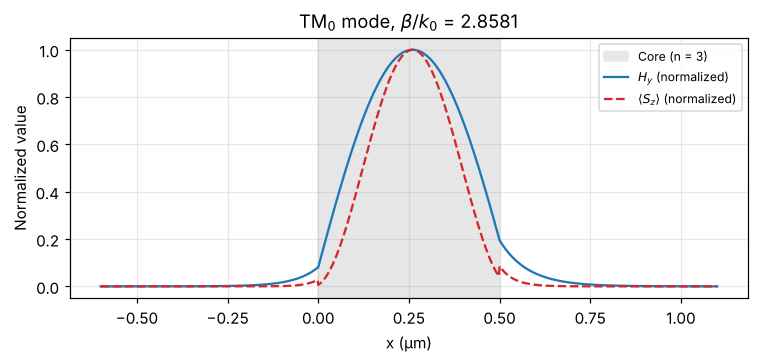

Fraction of guided power in the core: 0.984


In [10]:
b = beta_TM0
kx = np.sqrt(k0_wg**2 * n_co**2 - b**2)
g1, g2 = np.sqrt(b**2 - k0_wg**2 * n_cl1**2), np.sqrt(b**2 - k0_wg**2 * n_cl2**2)
C = n_co**2 * g1 / (n_cl1**2 * kx)

def Hy(x):
    core = np.cos(kx * x) + C * np.sin(kx * x)
    Hd = np.cos(kx * d_core) + C * np.sin(kx * d_core)
    return np.where(x < 0, np.exp(g1 * x), np.where(x <= d_core, core, Hd * np.exp(-g2 * (x - d_core))))

def eps_r(x):
    return np.where(x < 0, n_cl1**2, np.where(x <= d_core, n_co**2, n_cl2**2))

# Continuity of (1/eps) dHy/dx at x = d (core side vs cladding side)
dcore = kx * (-np.sin(kx * d_core) + C * np.cos(kx * d_core)) / n_co**2
dclad = -g2 * Hy(np.array(d_core)) / n_cl2**2
assert abs(dcore - dclad) < 1e-6 * abs(dcore)

x = np.linspace(-0.6e-6, 1.1e-6, 800)
omega_wg = 2 * np.pi * 299_792_458 / lam_wg
Sz = b * np.abs(Hy(x)) ** 2 / (2 * omega_wg * eps_r(x) * 8.854187817e-12)
core_fraction = np.trapezoid(Sz[(x >= 0) & (x <= d_core)], x[(x >= 0) & (x <= d_core)]) / np.trapezoid(Sz, x)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(0, d_core * 1e6, color="0.9", label="Core (n = 3)")
ax.plot(x * 1e6, Hy(x) / np.abs(Hy(x)).max(), "C0", label="$H_y$ (normalized)")
ax.plot(x * 1e6, Sz / Sz.max(), "C3--", label="$\\langle S_z \\rangle$ (normalized)")
ax.set(xlabel="x (µm)", ylabel="Normalized value", title=f"TM$_0$ mode, $\\beta/k_0$ = {b / k0_wg:.4f}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Fraction of guided power in the core: {core_fraction:.3f}")

`<S_z>` jumps at each interface because $H_y$ is continuous while $1/\varepsilon$ is not; this is why the core term must use $\varepsilon_{co}$.

## Notes on the original coursework

The 2015 MATLAB script for problem 2b ([source](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/dielectric-slab-boundaries)) used the cladding-1 permittivity in the core's Poynting-vector term and the cladding-1 decay constant in cladding 2. That made the plotted core power about 4.5 times too large and gave cladding 2 the wrong decay rate. The version above uses $\varepsilon_{co}$ in the core and $\gamma_2$ in cladding 2, and checks the interface conditions directly.

## References

- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press, 1999, sec. 1.6.
- S. J. Byrnes, "Multilayer optical calculations," arXiv:1603.02720, 2016.
- P. Yeh, *Optical Waves in Layered Media*, Wiley, 1988.
- K. Okamoto, *Fundamentals of Optical Waveguides*, 2nd ed., Academic Press, 2006, ch. 2.